# `lcz_get_planetary_computer` Tutorial — Microsoft Planetary Computer products, cropped to an LCZ map

Downloads any keyless/anonymous, globally-covering Planetary Computer STAC
collection (optical imagery, land cover, biodiversity, elevation, surface
water, ...), cropped to an existing LCZ map's footprint. No API key required
— assets are signed on the fly via `planetary_computer.sign_inplace`, the
same mechanism `lcz_get_lst` uses for Sentinel-3.

Run cells top-to-bottom. §1 downloads the LCZ map used by every later section.

**Built-in shortcuts (`PC_COLLECTIONS`)** — verified live against the
Planetary Computer STAC catalog while writing this tutorial:

| shortcut | collection id | assets | notes |
|---|---|---|---|
| `sentinel-2-l2a` | `sentinel-2-l2a` | B04,B03,B02,B08 | optical, 10m, cloud filter |
| `landsat` | `landsat-c2-l2` | red,green,blue,nir08 | optical, 30m, cloud filter |
| `worldcover` | `esa-worldcover` | map | land cover, 10m, static |
| `landcover-cci` | `esa-cci-lc` | lccs_class | land cover, 300m, annual |
| `biodiversity` | `io-biodiversity` | data | biodiversity intactness, ~300m, static |
| `elevation` | `nasadem` | elevation | elevation, 30m, static |
| `surface-water` | `jrc-gsw` | occurrence | water occurrence %, 30m, static |

Any other Planetary Computer collection also works — pass its raw id plus
`assets=[...]` (§10 shows `lcz_list_pc_assets` for discovering asset keys).


In [ ]:
import sys, os
sys.path.insert(0, os.getcwd())

import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

from LCZ4py import lcz_get_map
from LCZ4py import lcz_get_planetary_computer, lcz_list_pc_assets, PC_COLLECTIONS
from LCZ4py import lcz_plot_map
from LCZ4py import lcz_get_indices
from LCZ4py import lcz_cal_indices
from LCZ4py import lcz_plot_parameters


def to_rgb(array, band_idx=(0, 1, 2), pct=(2, 98)):
    # Percentile-stretch 3 bands of a (n_bands, H, W) stack into an RGB image.
    rgb = np.stack([array[i] for i in band_idx], axis=-1).astype(np.float32)
    out = np.zeros_like(rgb)
    for b in range(3):
        band = rgb[..., b]
        valid = ~np.isnan(band)
        if not valid.any():
            continue
        lo, hi = np.nanpercentile(band, pct)
        out[..., b] = np.clip((band - lo) / (hi - lo + 1e-9), 0, 1)
    return np.nan_to_num(out)

---
## 1 — Download an LCZ map (Berlin)


In [2]:
map_path = lcz_get_map(city="Berlin", isave_map=False)
print("map_path:", map_path)

import rasterio
with rasterio.open(map_path) as _src:
    lcz_valid_px = int(((_src.read(1) >= 1) & (_src.read(1) <= 17)).sum())
print("LCZ map footprint:", lcz_valid_px, "valid pixels")


map_path: /Users/co2map/.lcz4r_cache/clipped_2ed1dcfe644b4c6b.tif
LCZ map footprint: 146154 valid pixels


---
## 2 — Sentinel-2 L2A (optical, 10m, global)

Time-varying: requires `start_date`/`end_date` together. `max_cloud_cover`
filters on the STAC `eo:cloud_cover` property server-side. Berlin sits on a
UTM-zone/tile boundary, so several Sentinel-2 tiles are merged (best cloud
cover first) to fully cover the LCZ footprint.


In [3]:
t0 = time.time()
s2 = lcz_get_planetary_computer(
    map_path, collection="sentinel-2-l2a",
    start_date="2024-06-01", end_date="2024-08-31",
    max_cloud_cover=20,
)
print(f"done in {time.time()-t0:.1f}s")
print("bands:", s2.bands)
print("shape (bands, H, W):", s2.array.shape)
print("items used:", s2.item_ids)
valid_px = int((~np.isnan(s2.array[0])).sum())
print(f"footprint coverage: {valid_px}/{lcz_valid_px} LCZ pixels filled ({valid_px/lcz_valid_px:.1%})")


done in 0.0s
bands: ['B04', 'B03', 'B02', 'B08']
shape (bands, H, W): (4, 377, 750)
items used: ['S2A_MSIL2A_20240828T102021_R065_T32UQD_20240828T150452', 'S2B_MSIL2A_20240813T101559_R065_T33UUT_20240813T133715', 'S2B_MSIL2A_20240813T101559_R065_T33UUU_20240813T133715', 'S2B_MSIL2A_20240813T101559_R065_T33UVU_20240813T133715']
footprint coverage: 146154/146154 LCZ pixels filled (100.0%)


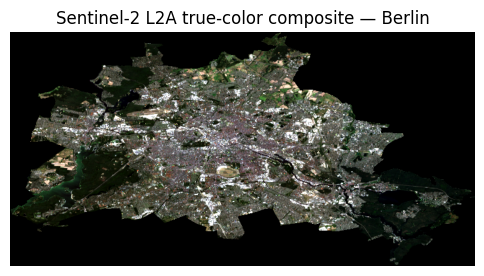

In [4]:
rgb = to_rgb(s2.array, band_idx=(0, 1, 2))  # B04, B03, B02 = R, G, B
plt.figure(figsize=(6, 6))
plt.imshow(rgb)
plt.title("Sentinel-2 L2A true-color composite — Berlin")
plt.axis("off")
plt.show()


### 2.1 — Static single-band plot via `lcz_plot_map`

`lcz_plot_map` auto-detects the stack as continuous data (float dtype) and
plots one band by its description — here `"B08"` (NIR). The figure is a
static matplotlib figure by default; pass `renderer="plotly"` for the
interactive Plotly figure.


In [ ]:
plot_s2 = lcz_plot_map(s2.path, band="B08", title="Sentinel-2 NIR (B08) — Berlin")
display(plot_s2.fig)

---
## 3 — Landsat Collection 2 Level-2 (optical, 30m, global)

Same pattern, different collection — coarser resolution, longer revisit.


In [6]:
t0 = time.time()
ls = lcz_get_planetary_computer(
    map_path, collection="landsat",
    start_date="2024-06-01", end_date="2024-08-31",
    max_cloud_cover=20,
)
print(f"done in {time.time()-t0:.1f}s")
print("bands:", ls.bands, "shape:", ls.array.shape, "items:", ls.item_ids)


done in 0.0s
bands: ['red', 'green', 'blue', 'nir08'] shape: (4, 377, 750) items: ['LC08_L2SP_193023_20240824_02_T1', 'LC08_L2SP_193024_20240824_02_T1']


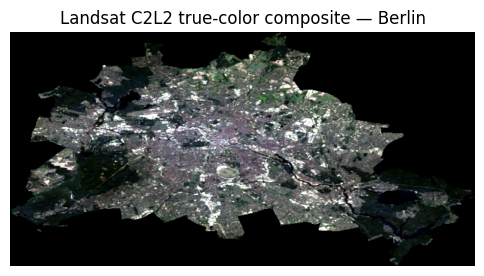

In [7]:
rgb_ls = to_rgb(ls.array, band_idx=(0, 1, 2))  # red, green, blue
plt.figure(figsize=(6, 6))
plt.imshow(rgb_ls)
plt.title("Landsat C2L2 true-color composite — Berlin")
plt.axis("off")
plt.show()


---
## 4 — ESA WorldCover (categorical land cover, 10m, static)

Static collections need no `start_date`/`end_date`. WorldCover is
categorical (discrete class codes), so the shortcut defaults to
`resampling="nearest"` — never blend land-cover codes with bilinear
interpolation.


In [8]:
t0 = time.time()
wc = lcz_get_planetary_computer(map_path, collection="worldcover")
print(f"done in {time.time()-t0:.1f}s")
print("bands:", wc.bands, "shape:", wc.array.shape, "items:", wc.item_ids)
print("classes present:", sorted(int(v) for v in np.unique(wc.array[~np.isnan(wc.array)])))


done in 0.0s
bands: ['map'] shape: (1, 377, 750) items: ['ESA_WorldCover_10m_2021_v200_N51E012']
classes present: [10, 30, 40, 50, 60, 80, 90]


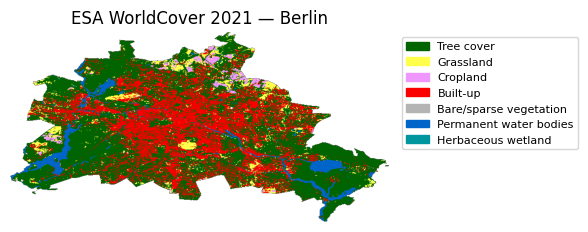

In [9]:
WORLDCOVER_CLASSES = {
    10: ("Tree cover", "#006400"), 20: ("Shrubland", "#ffbb22"),
    30: ("Grassland", "#ffff4c"), 40: ("Cropland", "#f096ff"),
    50: ("Built-up", "#fa0000"), 60: ("Bare/sparse vegetation", "#b4b4b4"),
    70: ("Snow and ice", "#f0f0f0"), 80: ("Permanent water bodies", "#0064c8"),
    90: ("Herbaceous wetland", "#0096a0"), 95: ("Mangroves", "#00cf75"),
    100: ("Moss and lichen", "#fae6a0"),
}

from matplotlib.colors import ListedColormap, BoundaryNorm
import matplotlib.patches as mpatches

present = sorted(int(v) for v in np.unique(wc.array[~np.isnan(wc.array)]))
colors = [WORLDCOVER_CLASSES[c][1] for c in present]
cmap = ListedColormap(colors)
norm = BoundaryNorm(present + [present[-1] + 10], cmap.N)

plt.figure(figsize=(6, 6))
plt.imshow(wc.array[0], cmap=cmap, norm=norm)
plt.title("ESA WorldCover 2021 — Berlin")
plt.axis("off")
handles = [mpatches.Patch(color=WORLDCOVER_CLASSES[c][1], label=WORLDCOVER_CLASSES[c][0]) for c in present]
plt.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


---
## 5 — ESA CCI Land Cover (categorical, 300m, annual time series)

`landcover-cci` *is* time-varying (one map per year) — pass a date range to
pick a year. Class codes follow the LCCS scheme (many classes); shown here
with a qualitative colormap rather than a full legend.


done in 0.0s


bands: ['lccs_class'] shape: (1, 377, 750) items: ['C3S-LC-L4-LCCS-Map-300m-P1Y-2020-v2.1.1-N45E000']


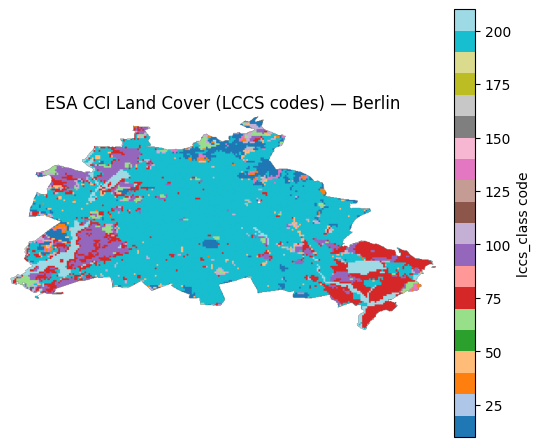

In [10]:
t0 = time.time()
cci = lcz_get_planetary_computer(
    map_path, collection="landcover-cci",
    start_date="2019-01-01", end_date="2020-12-31",
)
print(f"done in {time.time()-t0:.1f}s")
print("bands:", cci.bands, "shape:", cci.array.shape, "items:", cci.item_ids)

plt.figure(figsize=(6, 6))
plt.imshow(cci.array[0], cmap="tab20")
plt.title("ESA CCI Land Cover (LCCS codes) — Berlin")
plt.axis("off")
plt.colorbar(label="lccs_class code", fraction=0.046, pad=0.04)
plt.show()


---
## 6 — Global Biodiversity Intactness Index (continuous, ~300m, static)

Vizzuality/UNEP-WCMC's Biodiversity Intactness Index — a 0–1 ratio of
observed vs. reference-condition biodiversity. Continuous data, so the
default `resampling="bilinear"` is appropriate.

This collection actually publishes one composite per year; treating it as
"static" here just means no `start_date`/`end_date` filter is applied, so
the mosaic picks the most recent year first and falls back to older years
only to fill any tile-boundary gaps (see `item_ids` below — Berlin sits on a
tile edge, so 2017-2020 composites are blended).


In [11]:
t0 = time.time()
bio = lcz_get_planetary_computer(map_path, collection="biodiversity")
print(f"done in {time.time()-t0:.1f}s")
print("bands:", bio.bands, "shape:", bio.array.shape, "items:", bio.item_ids)
valid_px = int((~np.isnan(bio.array[0])).sum())
print(f"footprint coverage: {valid_px}/{lcz_valid_px} LCZ pixels filled ({valid_px/lcz_valid_px:.1%})")
print(f"mean intactness (within footprint): {np.nanmean(bio.array[0]):.3f}")


done in 0.0s
bands: ['data'] shape: (1, 377, 750) items: ['bii_2017_56.28265699726714_6.6627295177636086_cog', 'bii_2018_56.28265699726714_6.6627295177636086_cog', 'bii_2019_56.28265699726714_6.6627295177636086_cog', 'bii_2020_56.28265699726714_6.6627295177636086_cog']
footprint coverage: 136168/146154 LCZ pixels filled (93.2%)
mean intactness (within footprint): 0.399


In [ ]:
plot_bio = lcz_plot_map(bio.path, band="data", title="Biodiversity Intactness Index — Berlin", colorscale="Viridis")
display(plot_bio.fig)

---
## 7 — NASADEM elevation (continuous, 30m, static)


done in 0.0s
bands: ['elevation'] shape: (1, 377, 750) items: ['NASADEM_HGT_n52e013']


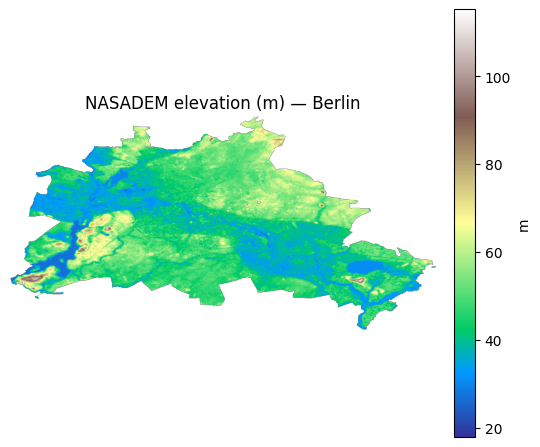

In [13]:
t0 = time.time()
elev = lcz_get_planetary_computer(map_path, collection="elevation")
print(f"done in {time.time()-t0:.1f}s")
print("bands:", elev.bands, "shape:", elev.array.shape, "items:", elev.item_ids)

plt.figure(figsize=(6, 6))
im = plt.imshow(elev.array[0], cmap="terrain")
plt.title("NASADEM elevation (m) — Berlin")
plt.axis("off")
plt.colorbar(im, label="m", fraction=0.046, pad=0.04)
plt.show()


---
## 8 — JRC Global Surface Water occurrence (continuous, 30m, static)

Percentage of the 1984-2021 Landsat archive each pixel was classified as
water — 0 (never) to 100 (always).


done in 0.0s
bands: ['occurrence'] shape: (1, 377, 750) items: ['10E_60Nv1_3_2020']


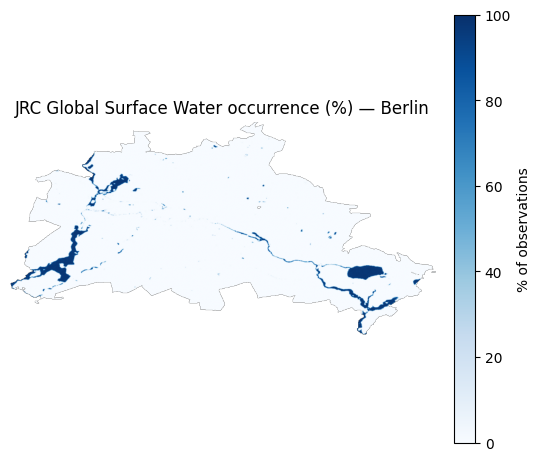

In [14]:
t0 = time.time()
water = lcz_get_planetary_computer(map_path, collection="surface-water")
print(f"done in {time.time()-t0:.1f}s")
print("bands:", water.bands, "shape:", water.array.shape, "items:", water.item_ids)

plt.figure(figsize=(6, 6))
im = plt.imshow(water.array[0], cmap="Blues", vmin=0, vmax=100)
plt.title("JRC Global Surface Water occurrence (%) — Berlin")
plt.axis("off")
plt.colorbar(im, label="% of observations", fraction=0.046, pad=0.04)
plt.show()


---
## 9 — Cache behavior

Repeating an identical call (same collection/assets/bbox/date range/cloud
filter) hits the on-disk cache instead of re-querying Planetary Computer.


In [15]:
cache_dir = "~/.lcz4r_cache"

t0 = time.time()
_ = lcz_get_planetary_computer(
    map_path, collection="elevation", cache=True, cache_dir=cache_dir, verbose=False,
)
first_call_s = time.time() - t0

t0 = time.time()
_ = lcz_get_planetary_computer(
    map_path, collection="elevation", cache=True, cache_dir=cache_dir, verbose=False,
)
second_call_s = time.time() - t0

print(f"first call:  {first_call_s:.2f}s")
print(f"second call: {second_call_s:.3f}s  (cache hit)")


first call:  0.01s
second call: 0.005s  (cache hit)


---
## 10 — Any other Planetary Computer collection

`PC_COLLECTIONS` is a curated shortlist, not an exhaustive one — Planetary
Computer hosts 100+ collections. For anything else, pass the raw collection
id plus `assets=[...]`. Use `lcz_list_pc_assets` to discover asset keys for
an area first.


In [16]:
print("built-in shortcuts:", list(PC_COLLECTIONS))

# Discover asset keys for a collection not in the registry (still keyless/free).
assets_available = lcz_list_pc_assets("nasadem", map_path)
print("\nnasadem assets (via raw collection id, for discovery):")
for key, title in assets_available.items():
    print(f"  {key!r}: {title}")


built-in shortcuts: ['sentinel-2-l2a', 'landsat', 'worldcover', 'biodiversity', 'landcover-cci', 'elevation', 'surface-water']



nasadem assets (via raw collection id, for discovery):
  'elevation': Elevation
  'tilejson': TileJSON with default rendering
  'rendered_preview': Rendered preview


In [17]:
# Using a raw collection id directly (bypassing the PC_COLLECTIONS shortcut)
# reproduces the same result as collection="elevation":
elev_raw = lcz_get_planetary_computer(
    map_path, collection="nasadem", assets=["elevation"], cache=False,
)
print("shape:", elev_raw.array.shape, "matches shortcut output:",
      np.allclose(elev_raw.array, elev.array, equal_nan=True))


shape: (1, 377, 750) matches shortcut output: True


---
## 11 — Error handling

An unrecognized collection id without explicit `assets=` raises a clear
error instead of guessing.


In [18]:
try:
    lcz_get_planetary_computer(map_path, collection="modis-13A1-061")
except ValueError as e:
    print("Raised as expected:")
    print(" ", e)


Raised as expected:
  Unknown collection shortcut {arg modis-13A1-061} — pass 'assets' explicitly.


---
## 12 — Real-world pipeline: spectral indices by LCZ class (Rio de Janeiro)

End-to-end test of the downstream indices pipeline built on top of
`lcz_get_planetary_computer`:

1. `lcz_get_map` — download a real LCZ map for a different city (Rio de
   Janeiro), to confirm none of this is Berlin-specific.
2. `lcz_get_planetary_computer` — Sentinel-2 L2A, requesting `B11` (SWIR)
   in addition to the RGB+NIR default so NDBI/MNDWI/NDMI/BSI are computable
   too, not just NDVI/EVI/SAVI/NDWI.
3. `lcz_get_indices` — compute all 8 spectral indices.
4. `lcz_cal_indices` — per-LCZ-class statistics + box/bar charts.
5. `lcz_plot_parameters` — spatial map of one index.


In [19]:
rio_map_path = lcz_get_map(city="Rio de Janeiro", isave_map=False)
print("Rio LCZ map:", rio_map_path)

with rasterio.open(rio_map_path) as _src:
    rio_valid_px = int(((_src.read(1) >= 1) & (_src.read(1) <= 17)).sum())
print("LCZ map footprint:", rio_valid_px, "valid pixels")


Rio LCZ map: /Users/co2map/.lcz4r_cache/clipped_dde886a46d0555c2.tif
LCZ map footprint: 129625 valid pixels


In [20]:
t0 = time.time()
rio_s2 = lcz_get_planetary_computer(
    rio_map_path, collection="sentinel-2-l2a",
    assets=["B04", "B03", "B02", "B08", "B11"],  # +B11 unlocks NDBI/MNDWI/NDMI/BSI
    start_date="2024-06-01", end_date="2024-09-30",
    max_cloud_cover=20,
)
print(f"done in {time.time()-t0:.1f}s")
print("bands:", rio_s2.bands, "shape:", rio_s2.array.shape)
print("items:", rio_s2.item_ids)


done in 0.0s
bands: ['B04', 'B03', 'B02', 'B08', 'B11'] shape: (5, 376, 777)
items: ['S2A_MSIL2A_20240909T130241_R095_T23KPQ_20240909T172150', 'S2B_MSIL2A_20240805T130249_R095_T23KPQ_20240805T181434']


### 12.1 — Compute indices

`lcz_get_indices` now carries **56 spectral indices** across five
categories — vegetation, water, urban/built-up, soil, and thermal (see
`INDEX_FORMULAS` for the full registry, ported from
`lcz_multi_app/lcz_parameters.py`'s ~75-formula set, scoped down to what's
a genuine per-pixel spectral formula computable from already
atmospherically-corrected reflectance). Only the indices whose required
bands are present in `rio_s2` get auto-selected — §13 revisits this with a
full Landsat band set (including SWIR2 and the thermal band) to unlock the
rest, including Land Surface Temperature.

Sentinel-2 L2A bands from Planetary Computer are raw digital numbers
(roughly 0-10000), not 0-1 reflectance. `lcz_get_indices` rescales them to
true surface reflectance internally before computing any index — without
that correction, EVI's fixed additive constants (calibrated for true
reflectance) blow up (verified: -1576..1956 on raw DN vs. a sane range once
scaled). Pure ratio indices like NDVI are scale-invariant and were already
correct either way, but the rescaling is applied uniformly for correctness
and because Landsat's scale factor also has a non-zero offset that *does*
affect ratio indices.


In [ ]:
from LCZ4py import INDEX_FORMULAS
print(f"Full registry: {len(INDEX_FORMULAS)} indices")

idx = lcz_get_indices(rio_s2, isave=True, verbose=False)
print(f"Computable from this Sentinel-2 stack (B04,B03,B02,B08,B11): {len(idx.indices)}")
print("indices computed:", idx.indices)
print("shape:", idx.array.shape)
for i, name in enumerate(idx.indices):
    arr = idx.array[i]
    print(f"  {name}: mean={np.nanmean(arr):.3f}  min={np.nanmin(arr):.3f}  max={np.nanmax(arr):.3f}")

### 12.2 — Per-LCZ-class statistics and charts

`lcz_cal_indices` masks each index by the LCZ class raster, aggregates
per-class descriptive statistics (mean/median/std/quantiles/95% CI), and
renders both chart kinds from that single aggregated table — a box plot
(distribution) and a bar chart (mean ± CI), both colored with the official
LCZ palette, as small-multiples across the requested indices.


In [22]:
stats = lcz_cal_indices(
    rio_map_path, idx, indices=["NDVI", "NDBI", "MNDWI"],
    plot_type="both",
    title="Spectral Indices by LCZ Class — Rio de Janeiro",
    subtitle="Sentinel-2 L2A, Jun-Sep 2024",
)

import polars as pl
with pl.Config(tbl_rows=20):
    print(stats.df.sort(["parameter", "lcz"]).select(
        ["parameter", "lcz", "lcz_name", "count", "mean", "median", "std", "ci_lower", "ci_upper"]
    ))


shape: (48, 9)
┌───────────┬─────┬────────────────────┬───────┬───┬───────────┬──────────┬───────────┬───────────┐
│ parameter ┆ lcz ┆ lcz_name           ┆ count ┆ … ┆ median    ┆ std      ┆ ci_lower  ┆ ci_upper  │
│ ---       ┆ --- ┆ ---                ┆ ---   ┆   ┆ ---       ┆ ---      ┆ ---       ┆ ---       │
│ str       ┆ i16 ┆ str                ┆ u64   ┆   ┆ f64       ┆ f64      ┆ f64       ┆ f64       │
╞═══════════╪═════╪════════════════════╪═══════╪═══╪═══════════╪══════════╪═══════════╪═══════════╡
│ MNDWI     ┆ 1   ┆ Compact highrise   ┆ 138   ┆ … ┆ -0.136284 ┆ 0.057155 ┆ -0.147215 ┆ -0.127973 │
│ MNDWI     ┆ 2   ┆ Compact midrise    ┆ 2077  ┆ … ┆ -0.209671 ┆ 0.03886  ┆ -0.210818 ┆ -0.207473 │
│ MNDWI     ┆ 3   ┆ Compact lowrise    ┆ 26350 ┆ … ┆ -0.241876 ┆ 0.034884 ┆ -0.240133 ┆ -0.239291 │
│ MNDWI     ┆ 4   ┆ Open highrise      ┆ 769   ┆ … ┆ -0.185246 ┆ 0.049176 ┆ -0.192084 ┆ -0.185122 │
│ MNDWI     ┆ 5   ┆ Open midrise       ┆ 801   ┆ … ┆ -0.223842 ┆ 0.048023 ┆ -0.226422

In [ ]:
display(stats.fig["box"])

In [ ]:
display(stats.fig["bar"])

### 12.3 — Spatial map of one index

`lcz_plot_parameters` works directly on the `lcz_get_indices` GeoTIFF stack
(no leading LCZ-class band, unlike `lcz_get_parameters` output — that's
what `has_class_band` controls) and resolves `iselect` by matching the
requested name against the file's real band descriptions.


In [ ]:
ndvi_fig = lcz_plot_parameters(
    idx.path, iselect="NDVI", title="NDVI — Rio de Janeiro (Sentinel-2 L2A)",
)
display(ndvi_fig)


---
## 13 — Full 56-index registry + thermal (Landsat)

Sentinel-2 has no thermal band, so §12 could only unlock indices needing
red/green/blue/nir/swir1. Requesting Landsat's full optical set *plus*
`lwir11` (its Surface Temperature band) unlocks the remaining
urban/soil/thermal indices — including Land Surface Temperature, read
directly from Landsat Collection 2 Level-2's already atmospherically
corrected ST product (more accurate than re-deriving brightness temperature
from raw thermal DN, which is what `lcz_multi_app`'s source app does).


In [26]:
t0 = time.time()
rio_ls_full = lcz_get_planetary_computer(
    rio_map_path, collection="landsat",
    assets=["red", "green", "blue", "nir08", "swir16", "swir22", "lwir11"],
    start_date="2024-06-01", end_date="2024-09-30",
    max_cloud_cover=20,
)
print(f"done in {time.time()-t0:.1f}s")
print("bands:", rio_ls_full.bands, "shape:", rio_ls_full.array.shape)
print("items:", rio_ls_full.item_ids)


done in 0.0s
bands: ['red', 'green', 'blue', 'nir08', 'swir16', 'swir22', 'lwir11'] shape: (7, 376, 777)
items: ['LC08_L2SP_217076_20240613_02_T1', 'LC08_L2SP_217076_20240629_02_T1', 'LC09_L2SP_217076_20240621_02_T1', 'LC09_L2SP_217076_20240707_02_T1', 'LC09_L2SP_217076_20240808_02_T1', 'LC09_L2SP_217076_20240824_02_T1', 'LC09_L2SP_217076_20240925_02_T1']


In [27]:
idx_full = lcz_get_indices(rio_ls_full, isave=True, verbose=False)
print(f"Computable from the full Landsat band set: {len(idx_full.indices)} / {len(INDEX_FORMULAS)}")
print("Missing (need bands this scene doesn't have):", sorted(set(INDEX_FORMULAS) - set(idx_full.indices)))


Computable from the full Landsat band set: 56 / 56
Missing (need bands this scene doesn't have): []


### 13.1 — Land Surface Temperature by LCZ class: a real UHI signal

If the pipeline is working, this should reproduce a textbook urban heat
island pattern: dense/paved LCZ classes hottest, water coldest.


In [ ]:
lst_stats = lcz_cal_indices(
    rio_map_path, idx_full, indices=["LST_C"], plot_type="bar",
    title="Land Surface Temperature by LCZ Class — Rio de Janeiro",
    subtitle="Landsat 8/9 Collection 2 Level-2 ST, Jun-Sep 2024",
)
with pl.Config(tbl_rows=20):
    print(lst_stats.df.sort("mean", descending=True).select(["lcz", "lcz_name", "count", "mean", "median"]))
display(lst_stats.fig)


### 13.2 — Ratio-index volatility: mean vs. median

Normalized-difference indices (NDVI-style, denominator is a *sum*) are
numerically stable. Pure single-band ratio indices — like RI, which divides
by a *cubed* band — are inherently prone to extreme values at low-
reflectance pixels (water, deep shadow), a property of how they're defined
in the literature, not a bug: the mean gets dragged around by a handful of
outlier pixels while the median stays sane. Prefer median/IQR over mean for
these (see the `lcz_get_indices` module docstring for the full list).


In [29]:
volatility_check = lcz_cal_indices(
    rio_map_path, idx_full, indices=["NDVI", "RI"], iplot=False,
)
with pl.Config(tbl_rows=20):
    print(volatility_check.sort(["parameter", "lcz"]).select(
        ["parameter", "lcz", "lcz_name", "mean", "median", "min", "max"]
    ))


shape: (32, 7)
┌───────────┬─────┬────────────────────┬────────────┬────────────┬───────────┬─────────────┐
│ parameter ┆ lcz ┆ lcz_name           ┆ mean       ┆ median     ┆ min       ┆ max         │
│ ---       ┆ --- ┆ ---                ┆ ---        ┆ ---        ┆ ---       ┆ ---         │
│ str       ┆ i16 ┆ str                ┆ f64        ┆ f64        ┆ f64       ┆ f64         │
╞═══════════╪═════╪════════════════════╪════════════╪════════════╪═══════════╪═════════════╡
│ NDVI      ┆ 1   ┆ Compact highrise   ┆ 0.17942    ┆ 0.15435    ┆ 0.070555  ┆ 0.4606      │
│ NDVI      ┆ 2   ┆ Compact midrise    ┆ 0.226953   ┆ 0.217722   ┆ 0.051347  ┆ 0.619071    │
│ NDVI      ┆ 3   ┆ Compact lowrise    ┆ 0.241654   ┆ 0.23469    ┆ 0.047044  ┆ 0.682225    │
│ NDVI      ┆ 4   ┆ Open highrise      ┆ 0.33016    ┆ 0.322072   ┆ 0.09549   ┆ 0.610598    │
│ NDVI      ┆ 5   ┆ Open midrise       ┆ 0.360119   ┆ 0.348064   ┆ 0.080281  ┆ 0.747239    │
│ NDVI      ┆ 6   ┆ Open lowrise       ┆ 0.442887   ┆ 0

---
## 14 — Beyond box/bar: effect size, scatter, radar, correlation

Ideas extracted from `lcz_multi_app/app.py` while auditing it for reusable
patterns — that Streamlit app's own "statistics" (correlation, Cohen's d,
UHI intensity, discrimination score) all turned out to be `np.random.*`
placeholders, never actually computed from real pixel values. Nothing
numeric was portable, but four *chart types* it aims for were worth adding
here for real: effect size, index-vs-index scatter, per-class radar
profile, and inter-index correlation. `lcz_cal_indices` also gained a
`type` column (Built-up LCZ 1-10 / Natural LCZ 11-17 — the standard
Stewart & Oke split) alongside the 17-class breakdown.


### 14.1 — Effect size (Cohen's d): which indices separate urban from natural?

A real Cohen's d — `(mean_urban - mean_natural) / pooled_std` between LCZ
1-10 and LCZ 11-17 — computed from the actual pixel values, not a random
number. Sorted by \|d\|, so this chart also works as a "Top-N most
discriminating index" ranking. Reference lines mark the conventional
0.2/0.5/0.8 small/medium/large thresholds.


In [ ]:
effect_size_stats = lcz_cal_indices(
    rio_map_path, idx_full, plot_type="effect_size",
    title="Which Indices Best Separate Urban from Natural? — Rio de Janeiro",
)
with pl.Config(tbl_rows=15):
    print(effect_size_stats.cohens_d.sort("cohens_d", descending=True).head(10))
    print("...")
    print(effect_size_stats.cohens_d.sort("cohens_d").head(10))
display(effect_size_stats.fig)


### 14.2 — NDVI vs NDBI scatter, sized by LST

Every pixel plotted as NDVI (x) vs NDBI (y), colored by its LCZ class
(official palette), sized by LST_C — a single view of how vegetation,
built-up-ness, and temperature relate pixel-by-pixel. Subsampled to 20k
points; a scatter with 130k+ points wouldn't show anything more but would
bloat the HTML file.


In [ ]:
scatter_stats = lcz_cal_indices(
    rio_map_path, idx_full, plot_type="scatter",
    index_x="NDVI", index_y="NDBI", size_by="LST_C",
    title="NDVI vs NDBI, sized by LST — Rio de Janeiro",
)
display(scatter_stats.fig)


### 14.3 — Radar: per-class profile across indices

The complement of §12-13's "one index across all classes" — here one LCZ
class is one trace, and the axes are several indices at once. Each axis is
min-max normalized across the plotted classes (`normalize_radar=True`,
the default) so indices with very different natural ranges (NDVI's -1..1
vs GSI's several units) stay visually comparable on the same chart.


In [ ]:
radar_stats = lcz_cal_indices(
    rio_map_path, idx_full, indices=["NDVI", "NDBI", "MNDWI", "BSI", "LST_C"],
    plot_type="radar", lcz_classes=[1, 3, 6, 11, 15, 17],
    title="LCZ Profile: NDVI/NDBI/MNDWI/BSI/LST — Rio de Janeiro",
)
display(radar_stats.fig)


### 14.4 — Correlation between indices

Pearson correlation over every valid pixel — useful both to sanity-check
expected relationships (NDVI should anti-correlate with NDBI and LST) and
to spot redundant indices (several formulas in the 56-index registry are
literally identical — e.g. LSWI/SOIL_MOISTURE/NDMI — and will show r=1.0).


In [ ]:
corr_stats = lcz_cal_indices(
    rio_map_path, idx_full,
    indices=["NDVI", "NDBI", "LST_C", "MNDWI", "NDMI", "LSWI", "SOIL_MOISTURE", "BSI"],
    plot_type="correlation",
    title="Spectral Index Correlation Matrix — Rio de Janeiro",
)
display(corr_stats.fig)


### 14.5 — `plot_type="all"`

One call, every applicable chart back as a dict (scatter only included
when `index_x`/`index_y` are given).


In [ ]:
all_stats = lcz_cal_indices(
    rio_map_path, idx_full, indices=["NDVI", "NDBI", "LST_C"],
    plot_type="all", index_x="NDVI", index_y="NDBI",
)
print("figures returned:", list(all_stats.fig.keys()))
print("df columns (note the new 'type' column):", all_stats.df.columns)
for panel_name, panel_fig in all_stats.fig.items():
    print(f"[{panel_name}]")
    display(panel_fig)


### 14.6 — Same charts via `lcz_plot_parameters`

`lcz_plot_parameters` now also accepts `chart_type="scatter"/"radar"/"correlation"`
as a convenience entry point — it just delegates to `lcz_cal_indices` under
the hood (`lcz_map=` plays the same role as `lcz_cal_indices`'s first
argument), so both spellings produce identical figures. Useful if
`lcz_plot_parameters` is already the module you import for plotting.


In [ ]:
fig_via_plot_parameters = lcz_plot_parameters(
    idx_full.path, lcz_map=rio_map_path, chart_type="scatter",
    index_x="NDVI", index_y="NDBI", size_by="LST_C",
    title="Same scatter, called via lcz_plot_parameters",
)
display(fig_via_plot_parameters)


---
## Summary

- `lcz_get_planetary_computer(lcz_map_path, collection, assets=None, start_date=None, end_date=None, max_cloud_cover=30, max_items=10, resampling=None, ...)`
  returns an `LCZPCResult` (`array`, `bands`, `collection`, `item_ids`, `path`).
- `collection` accepts a shortcut key from `PC_COLLECTIONS` (curated,
  verified list) or any raw Planetary Computer collection id + `assets=`.
- Time-varying collections (`sentinel-2-l2a`, `landsat`, `landcover-cci`)
  need `start_date`/`end_date` together; static ones (`worldcover`,
  `biodiversity`, `elevation`, `surface-water`) ignore them.
- `max_cloud_cover` filters optical collections server-side via
  `eo:cloud_cover`; ignored for collections without that property.
- Output is always a multi-band float32 GeoTIFF, NaN outside the LCZ map's
  valid pixels, pixel-aligned to its grid — one band per requested asset.
- `lcz_list_pc_assets(collection, lcz_map_path)` discovers asset keys for
  collections not in the built-in shortcut list.
- No API key needed for anything shown here — Planetary Computer assets are
  signed on the fly.
- Downstream (§12-14): `lcz_get_indices` computes 56 spectral indices across
  vegetation/water/urban/soil/thermal categories from a Sentinel-2/Landsat
  stack (rescaling raw DN to true reflectance first — and Landsat's thermal
  band to Kelvin via its own official scale, since it differs from the
  optical bands' scale); `lcz_plot_parameters(..., has_class_band=False)`
  maps any single index. Thermal indices (LST_K/LST_C) need Landsat's
  `lwir11` asset — not available for Sentinel-2. A handful of pure-ratio
  indices (RI, IRON_OXIDE, UTFVI, ...) are inherently volatile at
  low-reflectance pixels by definition — prefer their median over mean
  (§13.2).
- `lcz_cal_indices(..., plot_type=...)` covers `"box"`/`"bar"`/`"both"`
  (per-class stats), `"effect_size"` (real Cohen's d, built-up vs natural,
  doubling as a Top-N discrimination ranking), `"scatter"` (index-vs-index,
  colored by LCZ, optional `size_by`), `"radar"` (per-class profile across
  several indices, optionally normalized), `"correlation"` (Pearson matrix
  between indices), or `"all"` for every applicable figure at once (§14).
  The returned `df` always has a `type` (Built-up/Natural) column now.
- `lcz_plot_parameters(x, lcz_map=..., chart_type="scatter"/"radar"/"correlation", ...)`
  is a convenience alias for the three chart kinds above — it delegates to
  `lcz_cal_indices` rather than re-implementing them, so both spellings
  always produce identical figures (§14.6).
